## Denosisng (by run or by group)

With "by_run" ASVs are computed within each run separately, with "by_group" ASVs are computed at the group level.

Group level potentially allows for greater sensitivity on rare ASVs, but if the samples are not highly standardized there is a risk on introducing biases due to the treating of a dishomogeneous error source as homogeneous.

In [10]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("../")

import os
from os.path import join
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
from qiime2_utils import compile_manifest_files, update_runs_absolute_paths,full_preprocessing_pipeline

#### Make manifest files and data structure

In [12]:
base_path = "../DATA/"
preprocessing_type = ["by_group","by_run"][1]

# params
metadata_file_path  = join(base_path,"metadata/merged_metadata.parq")
raw_runs_folder     = join(base_path,"data/raw_reads/")
preprocessing_dir   = join(base_path,"data/preprocessing/denoising")
batch_size          = 5000
additional_groupby_fields = ["instrument_model"]

#%CAREFUL! may delete the whole preprocessing outcomes
full_preprocessing_path_cleaning = False

# run
manifest_file_paths = compile_manifest_files(raw_runs_folder=raw_runs_folder,
                                             preprocessing_dir=preprocessing_dir,
                                             metadata_file_path=metadata_file_path,
                                             additional_groupby_fields=additional_groupby_fields,
                                             batch_size=batch_size,
                                             full_preprocessing_path_cleaning=full_preprocessing_path_cleaning,
                                             preprocessing_type=preprocessing_type)


manifest_file_paths.to_csv(join(base_path,"metadata",f"{preprocessing_type}_manifest_file_paths.tsv"),sep="\t")

#### Preprocess

In [28]:
base_path = "../DATA/"
preprocessing_type = ["by_group","by_run"][1]

# import manifest file paths
manifest_file_paths = pd.read_csv(join(base_path,"metadata",f"{preprocessing_type}_manifest_file_paths.tsv"),sep="\t").pipe( lambda x : x.set_index(list(x.columns[:x.shape[1]-1])).iloc[:,-1])
update_runs_absolute_paths(manifest_file_paths) # ubdates raw_runs absolute paths in manifest files to match current system

# exec params
parallel = True
n_jobs   = 25

# computation params
cores       = 1 if parallel else 5  # with more than 1 core cutadapt fails when parallel=True
q_threshold = 30
clear_path  = True
from_step   = 0     # initial step of the preprocessing pipeline
to_step     = 3     # final step of the preprocessing pipeline (included)
overwrite   = False
skip_failed = False


# function compiled with assigned parameters
def compiled_function(manifest_file_path):
    import gc
    full_preprocessing_pipeline(manifest_file_path,
                                cores=cores,
                                q_threshold=q_threshold,
                                from_step=from_step,
                                to_step=to_step,
                                clear_path=clear_path,
                                overwrite=overwrite,
                                skip_failed=skip_failed)
    gc.collect()
    return None


# SEQUENTIAL [run over each group (defined by a manifest file)]
if not parallel:
    for manifest_file_path in manifest_file_paths:
        compiled_function(manifest_file_path)

# PARALLEL [run over each group (defined by a manifest file)]
elif parallel:
    from joblib import Parallel, delayed
    Parallel(n_jobs=n_jobs)(delayed(compiled_function)(mfp) for mfp in manifest_file_paths)



>>>> processing ../DATA/data/preprocessing/denoising/by_run/ERR5329047/manifest.tsv <<<
#samples = 1
Folder '../DATA/data/preprocessing/denoising/by_run/ERR5329047' has been cleared.
Folder '../DATA/data/preprocessing/denoising/by_run/ERR5329047' has been cleared.


-----------------------------------

0) import in qiime


>>>> processing ../DATA/data/preprocessing/denoising/by_run/ERR2308888/manifest.tsv <<<
#samples = 1


>>>> processing ../DATA/data/preprocessing/denoising/by_run/ERR2033342/manifest.tsv <<<
Folder '../DATA/data/preprocessing/denoising/by_run/ERR2308888' has been cleared.
Folder '../DATA/data/preprocessing/denoising/by_run/ERR2308888' has been cleared.


-----------------------------------

0) import in qiime
#samples = 1


>>>> processing ../DATA/data/preprocessing/denoising/by_run/ERR1843725/manifest.tsv <<<
Folder '../DATA/data/preprocessing/denoising/by_run/ERR2033342' has been cleared.
Folder '../DATA/data/preprocessing/denoising/by_run/ERR2033342' has been cl

/home/ubuntu/python/micromamba_envs/envs/qiime2-env/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ubuntu/python/micromamba_envs/envs/qiime2-env/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:182: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  context['result_data'] = pd.concat([context['result_data'], df])
/home/ubuntu/python/micromamba_envs/envs/qiime2-env/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf valu



-----------------------------------

2) compute truncation length


-----------------------------------

2) compute truncation length

=== Summary ===

Total reads processed:                  46,525
Reads with adapters:                        36 (0.1%)

== Read fate breakdown ==
Reads that were too short:                   0 (0.0%)
Reads written (passing filters):        46,525 (100.0%)

Total basepairs processed:     7,024,498 bp
Quality-trimmed:                       0 bp (0.0%)
Total written (filtered):      7,024,305 bp (100.0%)

=== Adapter 1 ===

Sequence: GGACTACNVGGGTWTCTAAT; Type: regular 3'; Length: 20; Trimmed: 19 times

Minimum overlap: 3
No. of allowed errors:
1-9 bp: 0; 10-19 bp: 1

Bases preceding removed adapters:
  A: 10.5%
  C: 31.6%
  G: 47.4%
  T: 10.5%
  none/other: 0.0%

Overview of removed sequences
length	count	expect	max.err	error counts
3	7	727.0	0	7
4	3	181.7	0	3
12	9	0.0	1	0 9


=== Adapter 2 ===

Sequence: GTGYCAGCMGCCGCGGTAA; Type: regular 5'; Length: 19

/home/ubuntu/python/micromamba_envs/envs/qiime2-env/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ubuntu/python/micromamba_envs/envs/qiime2-env/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ubuntu/python/micromamba_envs/envs/qiime2-env/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ubuntu/python/micromamba_envs/envs/qiime2-env/lib/python3.10/site-packages/seaborn



-----------------------------------

2) compute truncation length


-----------------------------------

2) compute truncation length


-----------------------------------

2) compute truncation length


-----------------------------------

2) compute truncation length


/home/ubuntu/python/micromamba_envs/envs/qiime2-env/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:182: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  context['result_data'] = pd.concat([context['result_data'], df])
/home/ubuntu/python/micromamba_envs/envs/qiime2-env/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:182: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  context['result_data'] = pd.concat([context['result_data'], df])
/home/ubuntu/python/micromamba_envs/

... (59 outputs left out)

Loading required package: Rcpp


.
5) Remove chimeras (method = consensus)
DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering 6) Report read numbers through the pipeline
7) Write output
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output
.
3) Learning Error Rates
.
5) Remove chimeras (method = consensus)
2420850 total bases in 16139 reads from 1 samples will be used for learning the error rates.
6) Report read numbers through the pipeline
7) Write output
4) Denoise samples 
.
3) Learning Error Rates
3484350 total bases in 23229 reads from 1 samples will be used for learning the error rates.
4) Denoise samples 
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output
4) Denoise samples 
.
5) Remove chimeras (method = consensus)
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output
6) Report read numbers through the pipeline
7) Write output
DADA2: 1.30.0 / Rcpp: 1.0

The filter removed all reads: /tmp/tmpv5ldundk/ERR1160661_0_L001_R1_001.fastq.gz not written.
Error: No reads passed the filter (was truncLen longer than the read length?)


.
3) Learning Error Rates
4545000 total bases in 30300 reads from 1 samples will be used for learning the error rates.
4) Denoise samples 
4) Denoise samples 
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output
4) Denoise samples 
4) Denoise samples 
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output


## Compute ASVs at different sensitivities


In [41]:

%load_ext autoreload
%autoreload 2
import sys
sys.path.append("../")

import os
from os.path import join
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [46]:
## step 3 denoise and ASVs extraction

from qiime2_utils import denoise_ASVs_extraction2
import qiime2

parallel = True
cores  = 1
n_jobs = 30

base_path = "../DATA/"
runsdir = join(base_path,"data/preprocessing/denoising/by_run")
Qiime_dir = [join(runsdir,run) for run in os.listdir(runsdir)]
    

# iterate over different omega_a values (default=1e-40)
#Omega_a = np.logspace(-10,-100,10)
#Omega_a = np.logspace(-1,-100,20)
Omega_a = [1e-1,1e-40,1e-100]


# function run in parallel over multiple threads
def thred_function(qiime_dir):

    # import previous steps results
    print("\n3) denoise and ASVs extraction")
    seq = qiime2.Artifact.load(join(qiime_dir,'1_seq_noprimers.qza'))
    with open(join(qiime_dir,"2_truncation_length.txt"),mode="r") as f:
        truncation_length=int(f.readline().split("=")[-1]) # import truncation length computed in previous steps

    if truncation_length>100:
        # ASV outputs containers
        Asv_tab   = []
        Asv_seq   = []
        Asv_stats = []
        
        # compute ASV for different amega_a values
        for omega_a in Omega_a:
            print(f"{qiime_dir}\n----[{omega_a=}]")
        
            # run
            asv_tab_, asv_seq_, asv_stats_ = denoise_ASVs_extraction2(seq,truncation_length,cores=cores,create_patch=False,omega_a=omega_a)
            
            # prepare output
            asv_tab = asv_tab_.to_dataframe()
            asv_seq = pd.DataFrame({"seq":{str(seq.metadata['id']): str(seq) for seq in list(asv_seq_)}})
            asv_stats = asv_stats_.to_dataframe()
            asv_stats["omega_a"] = omega_a
            asv_stats = asv_stats.reset_index().set_index(["sample-id","omega_a"])
        
            # store
            Asv_tab  .append(asv_tab  )
            Asv_seq  .append(asv_seq  )
            Asv_stats.append(asv_stats)
        
        
        # collect results into pandas format
        Asv_tab = pd.concat(Asv_tab,axis=1,keys=Omega_a).fillna(0)
        Asv_tab.columns = Asv_tab.columns.set_names(names=["omega_a","sample"])
        Asv_tab.index.name = "ASV_id"
        
        Asv_seq = pd.concat(Asv_seq).drop_duplicates()
        Asv_seq.columns.name="ASV_id"
        
        Asv_stats = pd.concat(Asv_stats)
        
        # save on disk
        savepath = join(qiime_dir,"3_asv")
        os.makedirs(savepath,exist_ok=True)
        Asv_tab.T.sparse.to_dense().to_parquet(join(savepath,"asv_tab.parq"  ))
        Asv_seq                    .to_parquet(join(savepath,"asv_seq.parq"  )) 
        Asv_stats                  .to_parquet(join(savepath,"asv_stats.parq")) 


from qiime2_utils import create_patched_r_script, apply_omega_a_patch
PATCHED_R_SCRIPT_PATH = "./patched_dada2/run_dada_patched.R"

# --- before the parallel call ---
create_patched_r_script(PATCHED_R_SCRIPT_PATH)  # once, in the main process


# SEQUENTIAL
if not parallel:
    for manifest_file_path in manifest_file_paths:
        compiled_function(manifest_file_path)

# PARALLEL
elif parallel:
    from joblib import Parallel, delayed
    Parallel(n_jobs=n_jobs)(delayed(thred_function)(qiime_dir) for qiime_dir in Qiime_dir)

Patched R script saved to: ./patched_dada2/run_dada_patched.R
OMEGA_A appears 21 times in patched script (expected 9)

3) denoise and ASVs extraction

3) denoise and ASVs extraction
../DATA/data/preprocessing/denoising/by_run/ERR1250604
----[omega_a=0.1]
Patch applied: _denoise_single now accepts omega_a and uses patched R script

3) denoise and ASVs extraction
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: /mnt/data300/projects/2026_ASV_clustering/ASV_extraction/patched_dada2/run_dada_patched.R --input_directory /tmp/qiime2/ubuntu/data/4a35bfb1-bf6f-4c51-abda-28b6a8746d6a/data --output_path /tmp/tmpxfgnjdio/output.tsv.biom --output_track /tmp/tmpxfgnjdio/track.tsv --filtered_directory /tmp/tmpxfgnjdio --truncation_length 150 --trim_left 0 --max_expected_errors 2.0 --truncation_quality_score 2

Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp
Loading required package: Rcpp


../DATA/data/preprocessing/denoising/by_run/ERR2579550
----[omega_a=0.1]
Patch already applied, skipping.
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: /mnt/data300/projects/2026_ASV_clustering/ASV_extraction/patched_dada2/run_dada_patched.R --input_directory /tmp/qiime2/ubuntu/data/ab38e583-1d2e-4a4f-8e1c-2fc839ccb72b/data --output_path /tmp/tmpyaqs44co/output.tsv.biom --output_track /tmp/tmpyaqs44co/track.tsv --filtered_directory /tmp/tmpyaqs44co --truncation_length 151 --trim_left 0 --max_expected_errors 2.0 --truncation_quality_score 2 --max_length Inf --pooling_method independent --chimera_method consensus --min_parental_fold 1.0 --allow_one_off False --num_threads 1 --learn_min_reads 1000000 --homopolymer_gap_penalty NULL --band_size 16 --omega_a 0.1

../DATA/data/preprocessing/denoisin

Loading required package: Rcpp
Loading required package: Rcpp


../DATA/data/preprocessing/denoising/by_run/ERR2306160
----[omega_a=0.1]
Patch already applied, skipping.
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: /mnt/data300/projects/2026_ASV_clustering/ASV_extraction/patched_dada2/run_dada_patched.R --input_directory /tmp/qiime2/ubuntu/data/7595b73c-ec14-4ab5-a210-12b1727be0a7/data --output_path /tmp/tmp8ja0z0b4/output.tsv.biom --output_track /tmp/tmp8ja0z0b4/track.tsv --filtered_directory /tmp/tmp8ja0z0b4 --truncation_length 150 --trim_left 0 --max_expected_errors 2.0 --truncation_quality_score 2 --max_length Inf --pooling_method independent --chimera_method consensus --min_parental_fold 1.0 --allow_one_off False --num_threads 1 --learn_min_reads 1000000 --homopolymer_gap_penalty NULL --band_size 16 --omega_a 0.1

R version 4.3.3 (2024-02-29) 
R ver

Loading required package: Rcpp
Loading required package: Rcpp


... (103 outputs left out)

Loading required package: Rcpp


DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering .
3) Learning Error Rates
13506150 total bases in 90041 reads from 1 samples will be used for learning the error rates.
4) Denoise samples 
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output
../DATA/data/preprocessing/denoising/by_run/ERR9735042
----[omega_a=1e-100]
Patch already applied, skipping.
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: /mnt/data300/projects/2026_ASV_clustering/ASV_extraction/patched_dada2/run_dada_patched.R --input_directory /tmp/qiime2/ubuntu/data/1a8817d3-7dd2-4472-ac2c-cb4db8e6bb1d/data --output_path /tmp/tmpg9rt6071/output.tsv.biom --output_track /tmp/tmpg9rt6071/track.tsv --filtered_directory /tmp/tmpg9rt6071 --truncation_length 150 --trim_left 0 --

Loading required package: Rcpp


.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output
DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering .
3) Learning Error Rates
8047200 total bases in 53648 reads from 1 samples will be used for learning the error rates.
4) Denoise samples 
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output


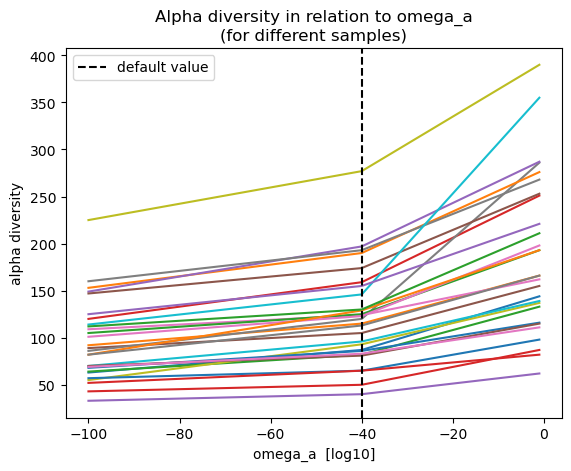

In [47]:
for qiime_dir in Qiime_dir:
    tab_filepath = join(qiime_dir,"3_asv","asv_tab.parq")
    if os.path.exists(tab_filepath):
        Asv_tab = pd.read_parquet(tab_filepath)
        f = (Asv_tab>0).sum(axis=1)
        y = f.values
        x = np.log10(f.index.get_level_values("omega_a"))
        plt.plot(x,y)#,label=qiime_dir.split("/")[-1])

plt.axvline(x=-40,linestyle="--",color="black",label="default value")
plt.title("Alpha diversity in relation to omega_a\n(for different samples)")
plt.xlabel("omega_a  [log10]")
plt.ylabel("alpha diversity")
plt.legend()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


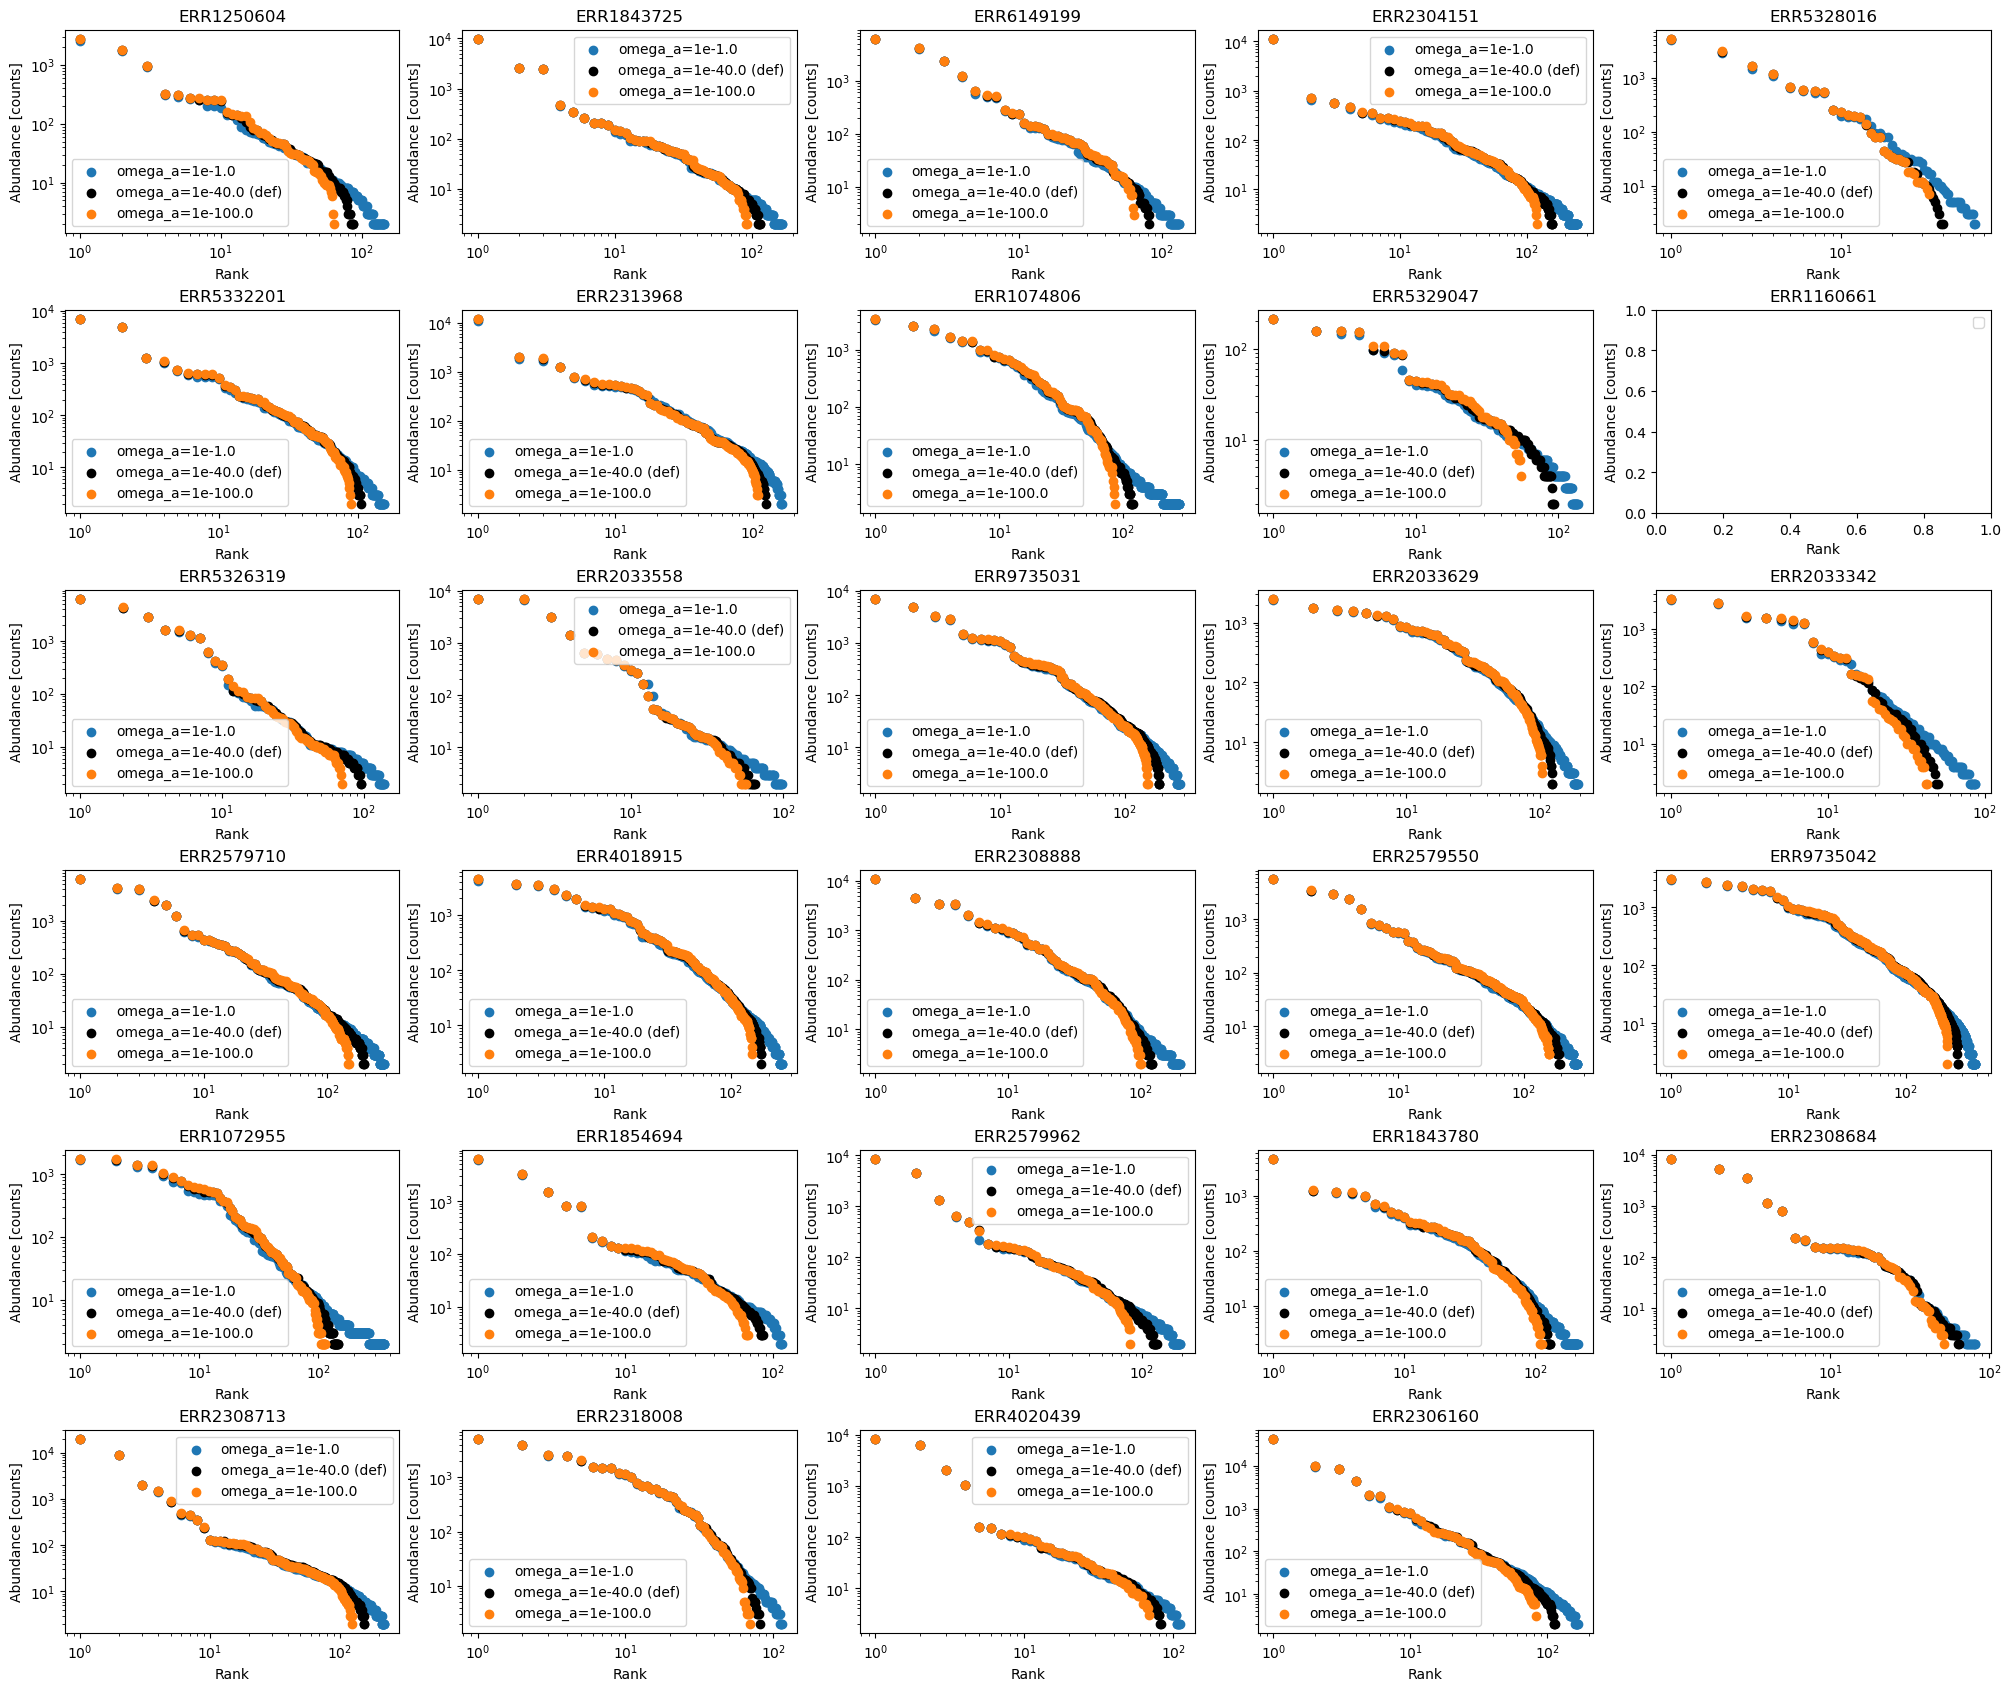

In [56]:
def compute_rank(x,axis=1):
    values = x.values
    ranks  = x.shape[axis]-np.argsort(np.argsort(x,axis=axis),axis=axis)
    return ranks, values

from utils import make_gridplot

fig, axs = make_gridplot(len(Qiime_dir))

for i,(ax,qiime_dir) in enumerate(zip(axs,Qiime_dir)):
    tab_filepath = join(qiime_dir,"3_asv","asv_tab.parq")
    if os.path.exists(tab_filepath):
        Asv_tab = pd.read_parquet(tab_filepath)

        x,y = compute_rank(Asv_tab)

        omega_a = np.log10(Asv_tab.index.get_level_values("omega_a"))
        ax.scatter(x[0 ,:],y[0 ,:],label=f"omega_a=1e{omega_a[ 0]}")
        ax.scatter(x[1 ,:],y[1 ,:],label=f"omega_a=1e{omega_a[ 1]} (def)",color="black")
        ax.scatter(x[-1,:],y[-1,:],label=f"omega_a=1e{omega_a[-1]}")
        ax.loglog()

    ax.set_title(qiime_dir.split("/")[-1])
    ax.set_ylabel("Abundance [counts]")
    ax.set_xlabel("Rank")
    ax.legend()

for j in range(i,len(axs)):
    axs[i].set_visible(False)

#### Consistency check between standard qiime2 pipeline, and patched pipeline with defatuld omega_a values

In [114]:
for qiime_dir in Qiime_dir:
    sample_id =  qiime_dir.split("/")[-1]

    # load the esult of standard qiime2 pipeline
    import qiime2
    import biom

    artifact_path = join(qiime_dir,"3_asv_tab.qza")
    if os.path.exists(artifact_path):
        asv_tab = qiime2.Artifact.load(artifact_path)
        counts_default = asv_tab.view(biom.Table).to_dataframe().iloc[:,0]
        counts_default


        # load result of patched qiime2 call with standard omega_a values (should me the same)
        idx = pd.IndexSlice

        tab_filepath = join(qiime_dir,"3_asv","asv_tab.parq")
        counts_default_pathced = pd.read_parquet(tab_filepath).loc[idx[1e-40,sample_id],:]
        counts_default_pathced = counts_default_pathced.iloc[(counts_default_pathced!=0).values] # remove zero-counts asv

        # consistency check
        result = (counts_default_pathced.loc[counts_default.index]==counts_default).all()
        print(sample_id,result)
    else:
        print(sample_id,"Missing")

ERR1250604 True
ERR1843725 True
ERR6149199 True
ERR2304151 True
ERR5328016 True
ERR5332201 True
ERR2313968 True
ERR1074806 True
ERR5329047 True
ERR1160661 Missing
ERR5326319 True
ERR2033558 True
ERR9735031 True
ERR2033629 True
ERR2033342 True
ERR2579710 True
ERR4018915 True
ERR2308888 True
ERR2579550 True
ERR9735042 True
ERR1072955 True
ERR1854694 True
ERR2579962 True
ERR1843780 True
ERR2308684 True
ERR2308713 True
ERR2318008 True
ERR4020439 True
ERR2306160 True
ERR1160451 Missing
